# Training your own model

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Training and evaluating a siamese change detection network on Sentinel-2 image pairs
</div>
<!-- markdownlint-enable MD033 -->

---

On the previous three pages you used ChangeStar, a model that arrived already trained. This page goes one step further: you train a {term}`siamese network <Siamese Network>` yourself, the FC-Siam-diff architecture introduced on the [deep learning page](04_deep-learning-for-change-detection.md), on labeled {term}`Sentinel-2` image pairs. All important choices are collected in one settings cell, so you can change them, re-run the page, and see for yourself which decisions actually matter.

---

## 1. Motivation

A pretrained model only helps if someone has already trained it for *your* kind of change. ChangeStar was built for buildings; if your project is about, say, gravel extraction, landslides or new greenhouses, there may be no suitable pretrained model, and you need to train one from labeled image pairs.

Training is also where most of the decisions that shape a model's quality are made: which {term}`spectral bands <Spectral Band>` to feed it, how large the training {term}`patches <Patch>` are, whether to use {term}`data augmentation <Data Augmentation>`, which {term}`loss function <Loss Function>` to use, and which {term}`probability threshold <Probability Threshold>` turns predictions into a change map. On a small dataset, these choices can make the difference between a model that barely works and one that clearly does.

---

## 2. Core idea

We train a binary change detector on **OSCD100**, a small teaching subset of the [Onera Satellite Change Detection (OSCD)](https://rcdaudt.github.io/oscd/) dataset: 100 pairs of 256×256-pixel Sentinel-2 images from cities around the world, each with a hand-drawn mask of urban change. The data are split into 60 training, 20 validation and 20 test pairs.

The workflow uses {term}`TorchGeo`, a {term}`PyTorch` library for geospatial deep learning, and follows the same pattern as every training workflow in this course:

1. Fit the model on the {term}`training set <Training Set>`.
2. Use the {term}`validation set <Validation Set>` to choose the best {term}`checkpoint <Checkpoint>`, to stop training early, and to tune the probability threshold.
3. Report the final scores once, on the untouched {term}`test set <Test Set>`.

```{admonition} Training takes a few minutes
:class: note
With the default settings, training takes about 3 minutes on an Apple M3 laptop (Apple GPU) and should be faster on a {term}`CUDA` {term}`GPU`. On a CPU-only machine, expect 15–30 minutes. The outputs shown on this page come from one such run, and your numbers will differ slightly.
```

---

## 3. Workflow

### A. Imports and experiment settings

In [1]:
import logging
import os
import tempfile
import time
import warnings
from pathlib import Path

import lightning as L
import matplotlib.pyplot as plt
import pandas as pd
import torch
from lightning.pytorch import Trainer
from lightning.pytorch.callbacks import Callback, EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

from torchgeo.datamodules import OSCD100DataModule
from torchgeo.datasets import OSCD100
from torchgeo.tasks import ChangeDetection

torch.set_float32_matmul_precision("medium")
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*exists and is not empty.*")
warnings.filterwarnings("ignore", ".*LeafSpec.*")
for name in ["lightning.pytorch", "lightning.fabric"]:  # hide routine status messages
    logging.getLogger(name).setLevel(logging.WARNING)

The next cell is the only one you need to edit. Every setting is explained in its comment and in the sections below. Run the page once with the defaults, then change **one** setting at a time and re-run everything, so you know which change caused a difference.

In [2]:
# ============================ EXPERIMENT SETTINGS ============================
# --- Model -------------------------------------------------------------------
MODEL = "fcsiamdiff"  # "fcsiamdiff": siamese U-Net with a ResNet encoder, any number of bands
                      # "btc": Swin Transformer + UPerNet, RGB only (slow without a CUDA GPU)
BACKBONE = "resnet18"  # fcsiamdiff: "resnet18", "resnet34", "resnet50" | btc: "swin_tiny"
PRETRAINED = True  # start from pretrained weights (ImageNet for ResNet, Cityscapes for BTC)
FREEZE_BACKBONE = False  # True: train only the decoder (faster, but less flexible)

# --- Data --------------------------------------------------------------------
BANDS = "all"  # "rgb" (3 bands) or "all" (all 13 Sentinel-2 bands); btc needs "rgb"
PATCH_SIZE = 256  # size of the random training crops: 64, 128 or 256 (= full image)
AUGMENT = True  # random flips and 90-degree rotations of the training pairs

# --- Loss and optimization ----------------------------------------------------
LOSS = "dice"  # "bce", "dice", "focal" or "jaccard"
POS_WEIGHT = 10.0  # extra weight for change pixels, only used with LOSS = "bce"
LR = 1e-3  # learning rate (use about 1e-4 for btc)
BATCH_SIZE = 8
MAX_EPOCHS = 100
PATIENCE = 30  # stop early if the validation F1 has not improved for this many epochs

# --- Evaluation and reproducibility --------------------------------------------
TUNE_THRESHOLD = True  # choose the probability threshold on the validation set (else 0.5)
SEED = 0  # random seed: change it to see how much results vary between runs
# ==============================================================================

band_list = OSCD100.rgb_bands if BANDS == "rgb" else OSCD100.all_bands
if MODEL == "btc" and BANDS != "rgb":
    raise ValueError("BTC uses an RGB-pretrained Swin Transformer: set BANDS = 'rgb'")

EXPERIMENT = (
    f"{MODEL}-{BACKBONE}_{BANDS}_p{PATCH_SIZE}_aug{int(AUGMENT)}_{LOSS}"
    f"_freeze{int(FREEZE_BACKBONE)}_lr{LR:g}_seed{SEED}"
)
L.seed_everything(SEED, workers=True)
print("Experiment:", EXPERIMENT)

Experiment: fcsiamdiff-resnet18_all_p256_aug1_dice_freeze0_lr0.001_seed0


`EXPERIMENT` turns the settings into a readable name. It is used for the output folders and for the comparison table at the end of the page, so every run stays identifiable, a small but useful habit for {term}`reproducibility <Reproducibility>`. `L.seed_everything(SEED)` fixes the {term}`random seed <Random Seed>`, so a re-run with the same settings gives (nearly) the same result.

| Setting | Default here | What it controls |
|---|---|---|
| `MODEL`, `BACKBONE` | `"fcsiamdiff"`, `"resnet18"` | Architecture and size of the shared encoder |
| `BANDS` | `"all"` | RGB only, or all 13 Sentinel-2 bands including {term}`near-infrared <Near-Infrared>` and {term}`shortwave infrared <Shortwave Infrared>` |
| `PATCH_SIZE` | `256` | How much spatial context each training example contains |
| `AUGMENT` | `True` | Random flips and rotations of the training pairs |
| `LOSS` | `"dice"` | What the model optimizes (see step D) |
| `FREEZE_BACKBONE` | `False` | Whether the pretrained encoder may adapt to satellite images |
| `MAX_EPOCHS`, `PATIENCE` | `100`, `30` | Maximum training length and {term}`early stopping <Early Stopping>` |
| `TUNE_THRESHOLD` | `True` | Choose the probability threshold on the validation set (see step H) |

### B. Download and inspect the data

Training pairs: 60
Image shape: (2, 3, 256, 256)  (time, bands, height, width)
Mask shape:  (1, 256, 256)
Changed pixels in this sample: 7.4%


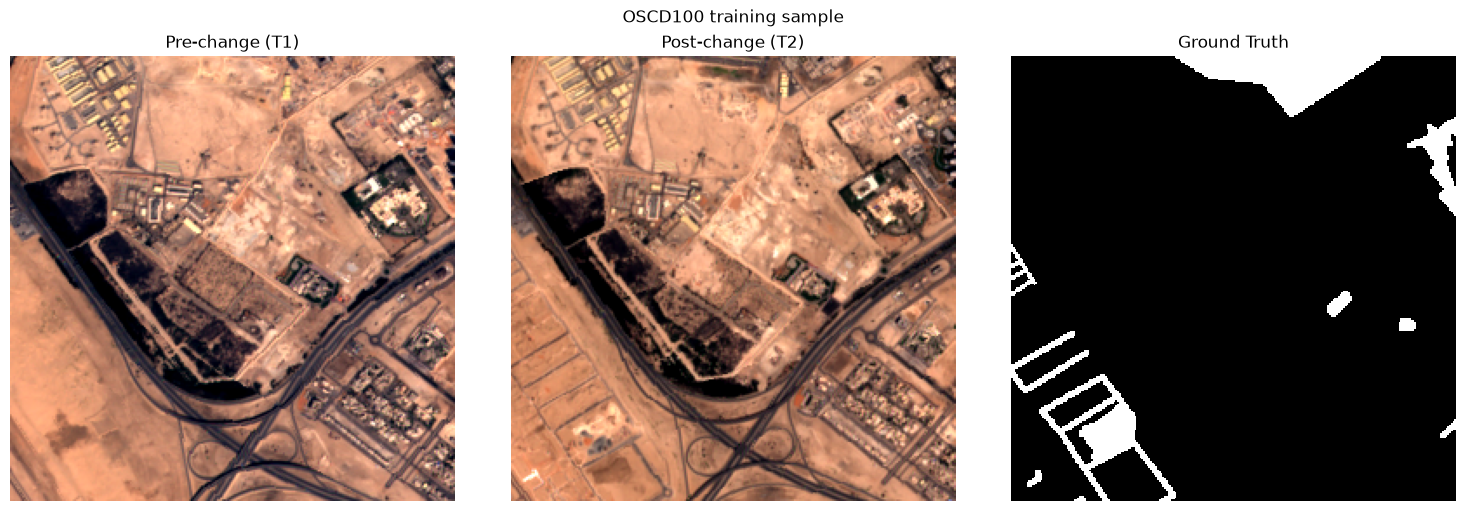

In [3]:
# OSCD100 is about 220 MB. It is stored in your system's temporary folder,
# outside the course repository, so it is never committed by accident.
root = os.path.join(tempfile.gettempdir(), "oscd100")
OUT_DIR = Path("oscd_runs")  # checkpoints, training logs and the results table
OUT_DIR.mkdir(exist_ok=True)

dataset = OSCD100(root=root, split="train", bands=OSCD100.rgb_bands, download=True)
sample = dataset[2]

print(f"Training pairs: {len(dataset)}")
print(f"Image shape: {tuple(sample['image'].shape)}  (time, bands, height, width)")
print(f"Mask shape:  {tuple(sample['mask'].shape)}")
print(f"Changed pixels in this sample: {100 * sample['mask'].float().mean():.1f}%")

fig = dataset.plot(sample, suptitle="OSCD100 training sample")
plt.show()

Each sample holds both dates in a single array of shape *(time, bands, height, width)*, plus a binary change mask drawn by an analyst. The images are 10 m Sentinel-2 data, much coarser than the 0.2 m VEXCEL imagery of the ChangeStar pages, so individual houses are only a few pixels wide, the {term}`mixed pixel <Mixed Pixel>` problem from the [change types page](02_change-types-and-challenges.md). The changes mapped in OSCD are therefore mostly larger construction sites and new neighborhoods.

Note also how few pixels change: typically only a few percent. This strong {term}`class imbalance <Class Imbalance>` shapes several of the choices below.

### C. Data loading and augmentation

TorchGeo's `OSCD100DataModule` downloads the data, splits it, normalizes every band and cuts random `PATCH_SIZE` crops for training. We extend it in two ways:

- **Augmentation.** With only 60 training pairs, a model quickly memorizes the training images, a form of {term}`overfitting <Overfitting>`. Random flips and 90° rotations create new, slightly different training examples in every {term}`epoch <Epoch>`. They are safe for satellite images, because a building seen from above is still a building after rotation. Crucially, **both dates and the mask** must receive exactly the same transformation; otherwise the model would learn to report "change" wherever the two images were rotated differently.
- **Full images for evaluation.** Validation and test always use the complete, unaugmented 256×256 images, so that scores are comparable between epochs and between experiments.

In [4]:
def flip_and_rotate(batch):
    """Apply the same random rotation and flip to both dates and the mask."""
    images, masks = batch["image"], batch["mask"]  # (B, T, C, H, W), (B, 1, H, W)
    for i in range(images.shape[0]):
        k = int(torch.randint(0, 4, (1,)))  # rotate by k * 90 degrees
        image = images[i].rot90(k, dims=(-2, -1))
        mask = masks[i].rot90(k, dims=(-2, -1))
        if torch.rand(1) < 0.5:  # mirror half of the samples
            image, mask = image.flip(-1), mask.flip(-1)
        images[i], masks[i] = image, mask
    return batch


class OSCD100AugDataModule(OSCD100DataModule):
    """OSCD100 with optional augmentation and full-size validation and test images."""

    def __init__(self, augment=True, **kwargs):
        super().__init__(**kwargs)
        self.augment = augment

    def setup(self, stage):
        super().setup(stage)
        if stage in ["fit", "validate"]:
            self.val_dataset = OSCD100(split="val", **self.kwargs)
        if stage == "test":
            self.test_dataset = OSCD100(split="test", **self.kwargs)

    def on_after_batch_transfer(self, batch, dataloader_idx):
        batch = super().on_after_batch_transfer(batch, dataloader_idx)  # normalization
        if self.augment and self.trainer is not None and self.trainer.training:
            batch = flip_and_rotate(batch)
        return batch


datamodule = OSCD100AugDataModule(
    root=root,
    bands=band_list,
    patch_size=PATCH_SIZE,
    augment=AUGMENT,
    batch_size=BATCH_SIZE,
    num_workers=0,  # the dataset is tiny, so loading in the main process is fine
    download=True,
)

`flip_and_rotate()` works on a whole batch on the training device. The dimensions `(-2, -1)` are always height and width, both for the five-dimensional image array and for the four-dimensional mask, which is what keeps image and mask aligned.

### D. Model and loss

`ChangeDetection` is TorchGeo's ready-made training module: it passes each image pair through the model, computes the loss and logs {term}`accuracy <Accuracy>`, {term}`precision <Precision>`, {term}`recall <Recall>`, {term}`F1-score` and {term}`IoU <Intersection over Union>`.

Two architectures are available via `MODEL`:

- **FC-Siam-diff** (`"fcsiamdiff"`, default) is a classic architecture by the same authors who created the OSCD dataset ([Daudt et al., 2018](https://arxiv.org/abs/1810.08462)). Both dates pass through the same {term}`ResNet` {term}`encoder <Backbone>` with shared weights, and the decoder works on the *difference* of their features: exactly the subtraction-based comparison described on the [deep learning page](04_deep-learning-for-change-detection.md). Because it is a {term}`convolutional network <Convolutional Neural Network>`, its first layer can be adapted to any number of bands, so it can use all 13 Sentinel-2 bands. The ImageNet weights still help: they are an example of {term}`transfer learning <Transfer Learning>`.
- **BTC** (`"btc"`) uses a {term}`Swin Transformer <Transformer>` encoder pretrained on Cityscapes street photos. It is about four times larger, accepts only RGB, and on Apple laptops it can only run on the CPU.

For the loss, plain binary cross-entropy (`"bce"`) treats every pixel equally. Because about 95% of all pixels are unchanged, a model can reach a low loss by predicting "no change" almost everywhere; `POS_WEIGHT` counteracts this by giving change pixels more weight. The {term}`Dice loss <Dice Loss>` (`"dice"`) instead measures the *overlap* between predicted and true change areas, which is essentially the F1-score, so the many easy background pixels cannot dominate it.

In [5]:
task = ChangeDetection(
    model=MODEL,
    backbone=BACKBONE,
    weights=PRETRAINED,
    freeze_backbone=FREEZE_BACKBONE,
    loss=LOSS,
    pos_weight=torch.tensor([POS_WEIGHT]) if LOSS == "bce" else None,
    in_channels=len(band_list),  # bands per date
    lr=LR,
)

n_params = sum(p.numel() for p in task.model.parameters())
print(f"{MODEL} with {BACKBONE}: {n_params / 1e6:.1f} million parameters")

fcsiamdiff with resnet18: 14.4 million parameters


### E. Train the model

The {term}`hyperparameters <Hyperparameter>` are set; what remains is the training loop itself. Lightning's `Trainer` runs it and calls three helpers after every epoch:

- `ModelCheckpoint` saves the model whenever the validation F1-score improves, so we can later reload the best epoch rather than the last one.
- `EarlyStopping` ends training once the validation F1-score has not improved for `PATIENCE` epochs.
- `CSVLogger` writes all metrics to a CSV file, which we plot in the next step.

A small custom callback prints a one-line summary every five epochs.

In [6]:
class PrintProgress(Callback):
    """Print a short progress line every few epochs."""

    def __init__(self, every=5):
        self.every = every

    def on_train_epoch_end(self, trainer, pl_module):
        epoch = trainer.current_epoch + 1
        if epoch % self.every == 0 or epoch == 1:
            m = trainer.callback_metrics
            print(
                f"epoch {epoch:3d} | train loss {m['train_loss']:.3f} | "
                f"val loss {m['val_loss']:.3f} | val F1 {m['val_AverageF1Score']:.3f}"
            )


# Hardware: CUDA GPU > Apple GPU (MPS) > CPU. BTC cannot run on MPS (its decoder
# uses a pooling operation that MPS does not support yet), so it uses the CPU there.
if torch.cuda.is_available():
    accelerator = "gpu"
elif torch.backends.mps.is_available() and MODEL != "btc":
    accelerator = "mps"
else:
    accelerator = "cpu"
print("Training on:", accelerator)

checkpoint_callback = ModelCheckpoint(
    monitor="val_AverageF1Score",
    mode="max",
    dirpath=OUT_DIR / "checkpoints" / EXPERIMENT,
    save_top_k=1,
)
early_stopping_callback = EarlyStopping(
    monitor="val_AverageF1Score", mode="max", patience=PATIENCE
)
logger = CSVLogger(save_dir=OUT_DIR / "logs", name=EXPERIMENT)

trainer = Trainer(
    accelerator=accelerator,
    devices=1,
    callbacks=[checkpoint_callback, early_stopping_callback, PrintProgress()],
    logger=logger,
    log_every_n_steps=1,
    max_epochs=MAX_EPOCHS,
    enable_progress_bar=False,
    enable_model_summary=False,
)

start = time.time()
trainer.fit(model=task, datamodule=datamodule)
print(f"\nStopped after {trainer.current_epoch} epochs ({(time.time() - start) / 60:.1f} min)")
print(f"Best validation F1: {checkpoint_callback.best_model_score:.3f}")

Training on: mps


epoch   1 | train loss 0.898 | val loss 0.922 | val F1 0.077


epoch   5 | train loss 0.729 | val loss 0.866 | val F1 0.139


epoch  10 | train loss 0.691 | val loss 0.859 | val F1 0.155


epoch  15 | train loss 0.499 | val loss 0.778 | val F1 0.242


epoch  20 | train loss 0.428 | val loss 0.809 | val F1 0.214


... (3 outputs left out)

epoch  40 | train loss 0.351 | val loss 0.700 | val F1 0.296


epoch  45 | train loss 0.432 | val loss 0.673 | val F1 0.334


epoch  50 | train loss 0.420 | val loss 0.665 | val F1 0.343



Stopped after 54 epochs (3.3 min)
Best validation F1: 0.436


`monitor="val_AverageF1Score"` makes the validation F1-score the criterion for both checkpointing and early stopping. We do not monitor accuracy here, for a reason that step G makes clear.

### F. Learning curves

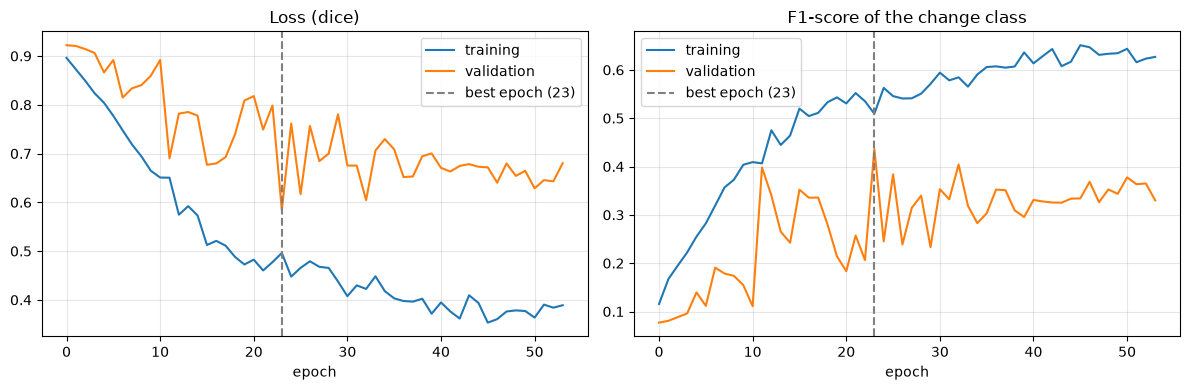

In [7]:
metrics = pd.read_csv(Path(logger.log_dir) / "metrics.csv")
per_epoch = metrics.groupby("epoch").mean(numeric_only=True)
best_epoch = per_epoch["val_AverageF1Score"].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(per_epoch.index, per_epoch["train_loss"], label="training")
axes[0].plot(per_epoch.index, per_epoch["val_loss"], label="validation")
axes[0].set_title(f"Loss ({LOSS})")
axes[1].plot(per_epoch.index, per_epoch["train_AverageF1Score"], label="training")
axes[1].plot(per_epoch.index, per_epoch["val_AverageF1Score"], label="validation")
axes[1].set_title("F1-score of the change class")
for ax in axes:
    ax.axvline(best_epoch, color="grey", ls="--", label=f"best epoch ({best_epoch})")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

Read these curves the same way as in L07. While training and validation curves improve together, the model is learning patterns that generalize; a gap that keeps widening, with training F1 still rising while validation F1 stalls, is the signature of overfitting.

In the run shown here, you will probably notice two things:

- **A clear gap** between training and validation F1. Part of it is overfitting to the 60 training pairs; part of it is simply that some validation images are harder than the training images. On a dataset this small, the two are difficult to separate.
- **A very bumpy validation curve.** It is computed from only 20 image pairs, so a few pixels more or less in one image visibly move the score. The "best" checkpoint (dashed line) may therefore sit on a lucky spike rather than on a genuinely better model. This is one reason why the final evaluation must happen on a separate test set.

```{admonition} Optional: TensorBoard
:class: tip
For interactive curves, replace `CSVLogger` with `lightning.pytorch.loggers.TensorBoardLogger` and run `tensorboard --logdir oscd_runs/logs` in a terminal. Each experiment then appears as a separate run that you can overlay with others.
```

### G. Evaluate on the test set

Only now do we touch the test set, using the best checkpoint.

In [8]:
test_metrics = trainer.test(
    model=task, datamodule=datamodule, ckpt_path="best", verbose=False
)[0]

pd.Series(
    {
        "Accuracy": test_metrics["test_OverallAccuracy"],
        "Precision": test_metrics["test_AveragePrecision"],
        "Recall": test_metrics["test_AverageRecall"],
        "F1-score": test_metrics["test_AverageF1Score"],
        "IoU": test_metrics["test_AverageJaccardIndex"],
    },
    name="test set, threshold 0.5",
).round(3).to_frame()

,"test set, threshold 0.5"
Accuracy,0.957
Precision,0.590
Recall,0.691
F1-score,0.637
IoU,0.467


Accuracy looks impressive, but remember that around 95% of the pixels are unchanged: a model that predicts "no change" everywhere would score almost as high while being completely useless. For change detection, **F1-score and IoU of the change class** are the metrics that matter. Precision tells you how many of the flagged pixels really changed (few false alarms); recall tells you how many of the real changes were found (few misses).

### H. Tune the probability threshold

As on the [previous page](07_thresholds-model-variants-and-exports.ipynb), the model outputs a change probability per pixel, and 0.5 is just a default cut-off. Here we have labeled validation data, so instead of judging thresholds visually we can measure which one gives the best F1-score.

```{admonition} Choose on validation, report on test
:class: important
The threshold is a decision you make, so it must be chosen on the validation set. Choosing it on the test set would make the test score optimistic, a form of {term}`data leakage <Data Leakage>`. The test set is used once, at the very end.
```

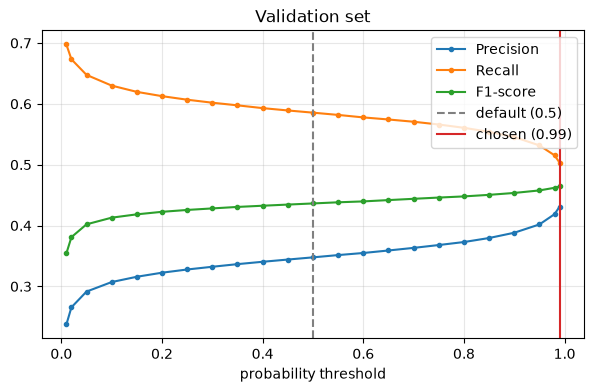

,Precision,Recall,F1-score,IoU
threshold 0.5,0.590,0.691,0.637,0.467
tuned threshold 0.99,0.666,0.614,0.639,0.469


In [9]:
best_task = ChangeDetection.load_from_checkpoint(checkpoint_callback.best_model_path)
best_task = best_task.to(task.device).eval()


def predict_split(split):
    """Return change probabilities and reference masks for all images of a split."""
    split_dataset = OSCD100(root=root, split=split, bands=band_list)
    probs, masks = [], []
    for item in split_dataset:
        image = datamodule.aug({"image": item["image"].float().unsqueeze(0)})["image"]
        with torch.no_grad():
            prob = best_task.predict_step({"image": image.to(best_task.device)}, 0)
        probs.append(prob.squeeze().cpu())
        masks.append(item["mask"].squeeze().bool())
    return torch.stack(probs), torch.stack(masks)


def scores(prob, mask, threshold):
    """Precision, recall, F1 and IoU of the change class at a given threshold."""
    pred = prob > threshold
    tp = (pred & mask).sum().item()
    fp = (pred & ~mask).sum().item()
    fn = (~pred & mask).sum().item()
    return {
        "Precision": tp / max(tp + fp, 1),
        "Recall": tp / max(tp + fn, 1),
        "F1-score": 2 * tp / max(2 * tp + fp + fn, 1),
        "IoU": tp / max(tp + fp + fn, 1),
    }


val_prob, val_mask = predict_split("val")
thresholds = [0.01, 0.02] + [t / 100 for t in range(5, 96, 5)] + [0.98, 0.99]
val_scores = pd.DataFrame([scores(val_prob, val_mask, t) for t in thresholds], index=thresholds)
threshold = val_scores["F1-score"].idxmax() if TUNE_THRESHOLD else 0.5

ax = val_scores[["Precision", "Recall", "F1-score"]].plot(figsize=(7, 4), marker=".")
ax.axvline(0.5, color="grey", ls="--", label="default (0.5)")
ax.axvline(threshold, color="C3", label=f"chosen ({threshold:.2f})")
ax.set_xlabel("probability threshold")
ax.set_title("Validation set")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

test_prob, test_mask = predict_split("test")
pd.DataFrame(
    {
        "threshold 0.5": scores(test_prob, test_mask, 0.5),
        f"tuned threshold {threshold:.2f}": scores(test_prob, test_mask, threshold),
    }
).T.round(3)

The plot shows the sensitivity-versus-specificity trade-off from the previous page as numbers: raising the threshold increases precision (fewer false alarms) and lowers recall (more missed changes). The F1-score summarizes both, and the threshold with the highest validation F1 is chosen.

How much tuning helps depends on the loss. With the default Dice loss, almost all predicted probabilities are very close to 0 or 1, so moving the threshold changes only a few pixels: the curves are fairly flat, and the test F1-score barely changes, even if the chosen threshold is far from 0.5. With `LOSS = "bce"`, the probabilities are spread out more, the F1 curve usually has a clear peak, and tuning often gains several F1 points; try it.

### I. Visualize predictions

Numbers summarize, but maps convince. We show the four test images with the most change, each with its own F1-score.

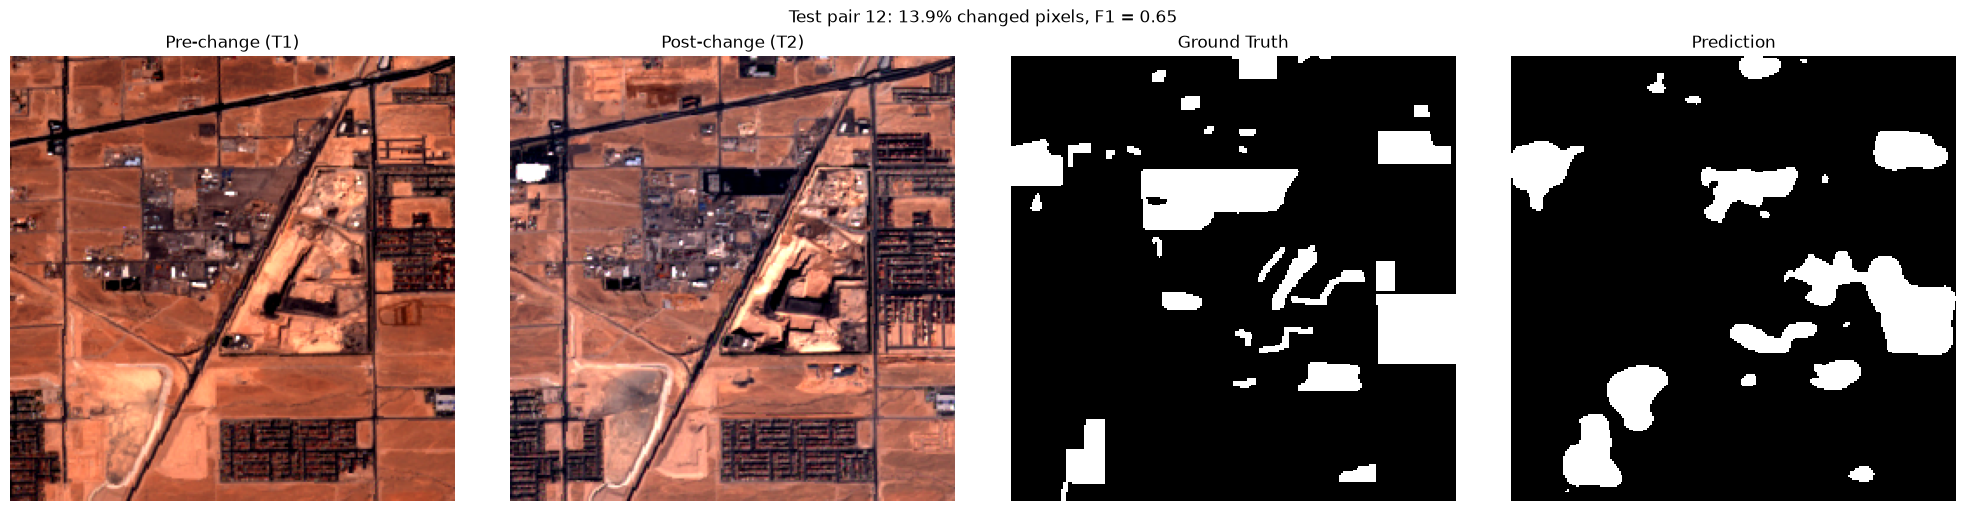

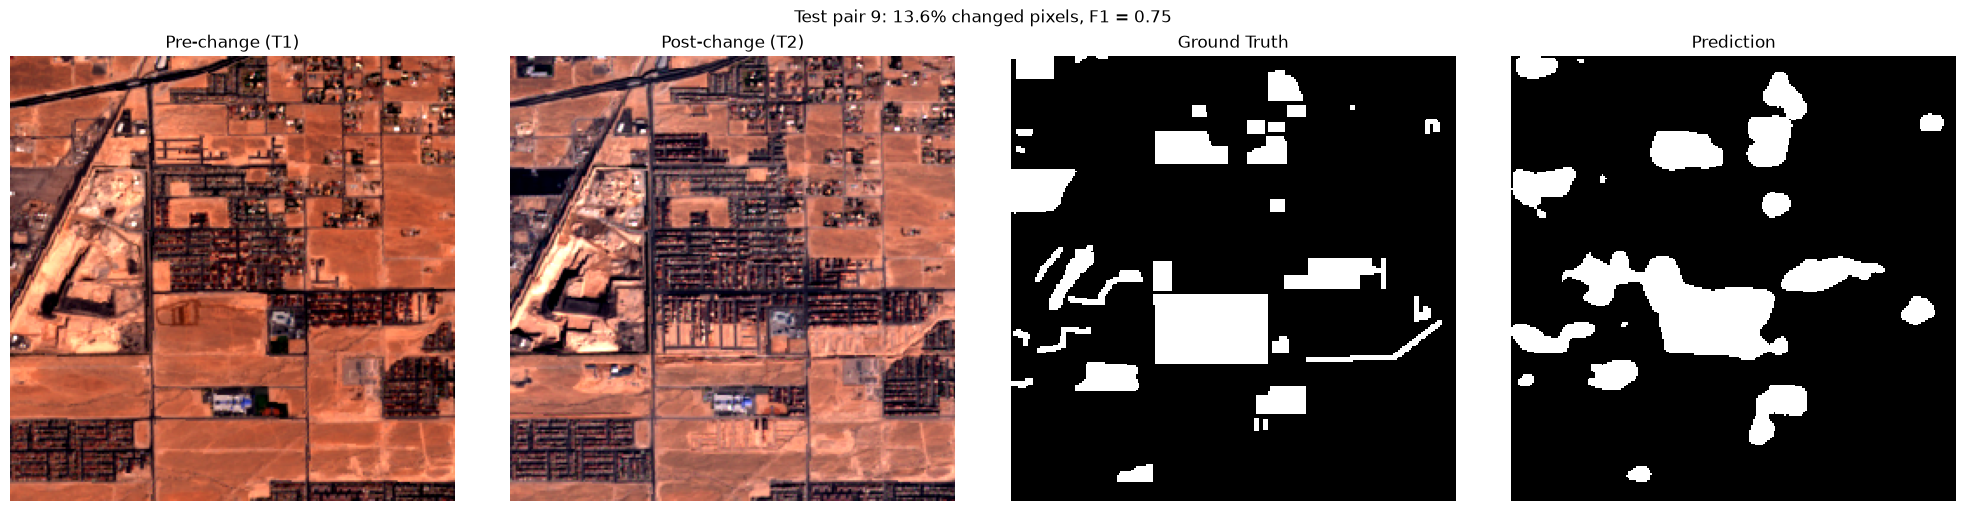

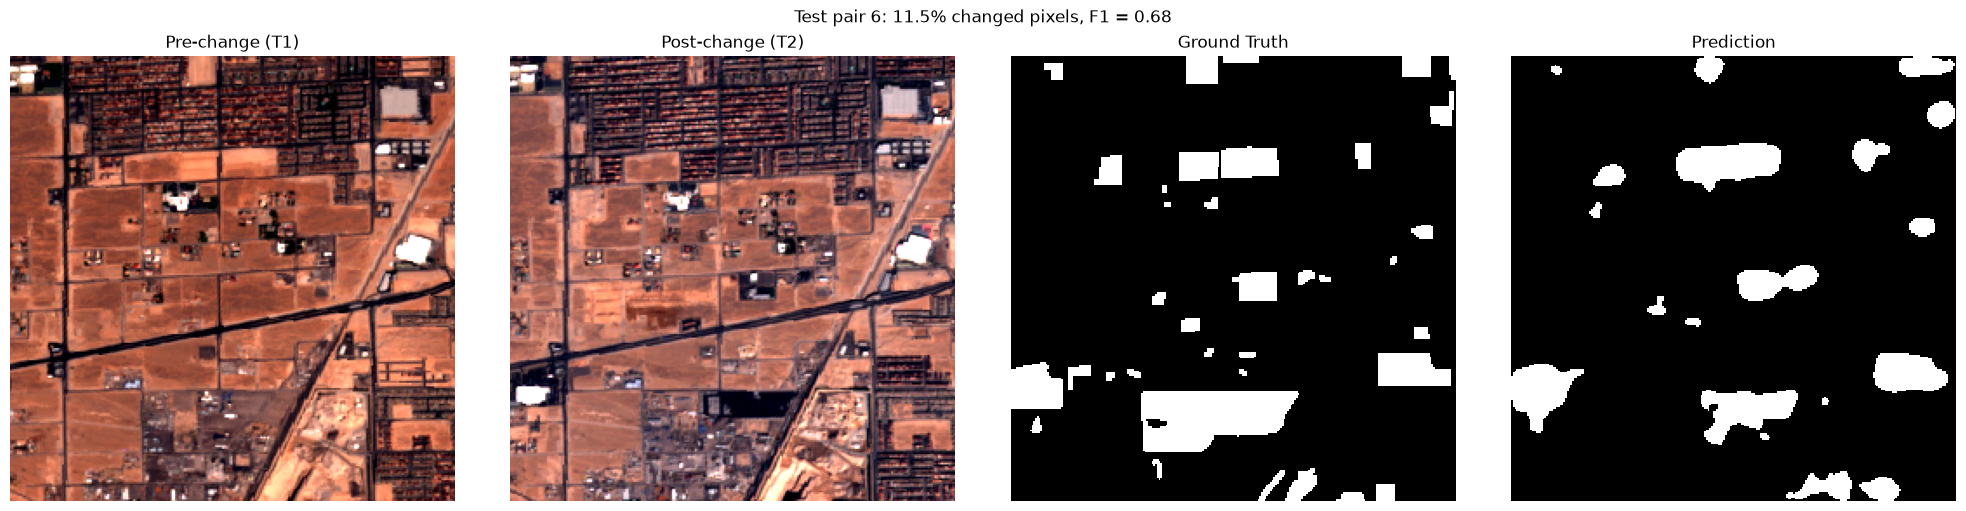

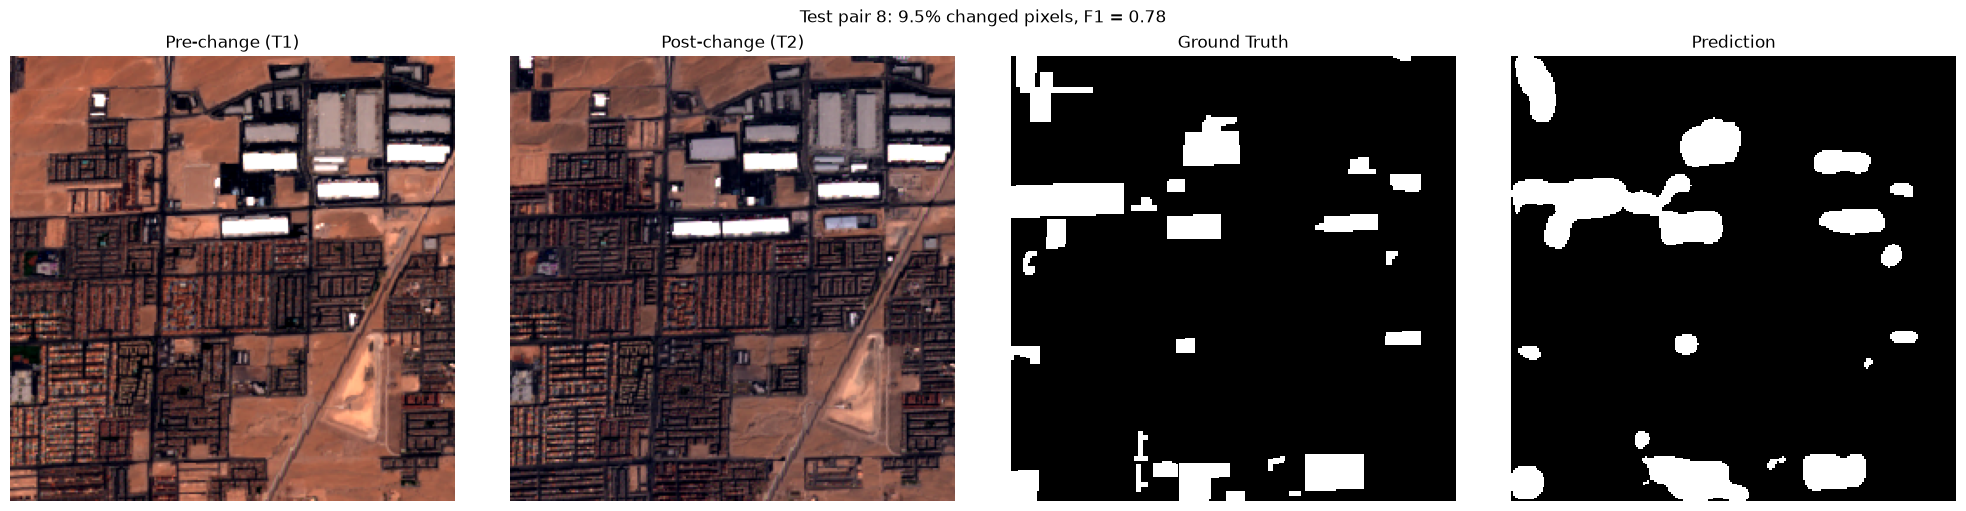

In [10]:
test_dataset = OSCD100(root=root, split="test", bands=band_list)
change_fraction = test_mask.float().mean(dim=(1, 2))
order = change_fraction.argsort(descending=True).tolist()

show = order[:4]  # order[-4:] shows the images with the least change
for idx in show:
    item = test_dataset[idx]
    item["prediction"] = (test_prob[idx] > threshold).float().unsqueeze(0)
    f1 = scores(test_prob[idx], test_mask[idx], threshold)["F1-score"]
    title = f"Test pair {idx}: {100 * change_fraction[idx]:.1f}% changed pixels, F1 = {f1:.2f}"
    fig = test_dataset.plot(item, suptitle=title)
    plt.show()

The OSCD test cities include **Las Vegas**, and the desert suburbs with their regular street grid in several of these pairs are most likely from there: the same kind of suburban growth as the Osaka housing estate on the ChangeStar pages, here seen at 10 m instead of 0.2 m resolution. Compare the prediction with the reference mask: the model captures most large construction areas, but its outlines are smoother and blobbier than the hand-drawn polygons, and narrow features such as new roads are often missed. Both are typical for 10 m data and a small training set.

Scenes with only a few small changes are much harder: set `show = order[-4:]` to look at them, and expect much lower F1-scores there.

### J. Compare your experiments

Each run appends its settings and test scores to a small CSV file, so the table grows as you experiment.

In [11]:
results_file = OUT_DIR / "results.csv"
final = scores(test_prob, test_mask, threshold)
row = {
    "model": f"{MODEL}-{BACKBONE}",
    "bands": BANDS,
    "patch": PATCH_SIZE,
    "augment": AUGMENT,
    "loss": LOSS,
    "frozen": FREEZE_BACKBONE,
    "seed": SEED,
    "epochs": trainer.current_epoch,
    "threshold": threshold,
    "F1@0.5": round(scores(test_prob, test_mask, 0.5)["F1-score"], 3),
    "F1": round(final["F1-score"], 3),
    "IoU": round(final["IoU"], 3),
}
results = pd.DataFrame([row])
if results_file.exists():
    results = pd.concat([pd.read_csv(results_file), results], ignore_index=True)
results.to_csv(results_file, index=False)
results.sort_values("F1", ascending=False)

,model,bands,patch,augment,loss,frozen,seed,epochs,threshold,F1@0.5,F1,IoU
0,fcsiamdiff-resnet18,all,256,True,dice,False,0,54,0.99,0.637,0.639,0.469


To give you a reference point, we ran a set of experiments on an Apple M3 Pro laptop (test set, threshold 0.5 unless noted). Each row changes one setting compared to the default:

| Setup | Test F1 | Test IoU |
|---|---|---|
| **Default:** FC-Siam-diff, all bands, 256 px, augmentation, Dice (3 seeds) | **0.64** (0.60–0.66) | **0.47** |
| RGB only instead of all 13 bands (3 seeds) | 0.56 (0.36–0.67) | 0.40 |
| 128 px instead of 256 px training patches | 0.42 | 0.26 |
| No augmentation | 0.59 | 0.42 |
| BCE instead of Dice loss (tuned threshold in brackets) | 0.63 (0.66) | 0.46 (0.49) |
| BTC, RGB, 64 px patches, no augmentation, BCE, frozen backbone | 0.44 | 0.28 |

What these runs suggest:

- **Spatial context matters most.** Smaller training patches cost far more than any other single choice.
- **Augmentation helps a small dataset**, by about 0.05 F1 here.
- **More bands make training more reliable.** With all 13 bands, three seeds all gave good results; with RGB only, one run was just as good but another one failed (F1 0.36).
- **Small datasets give noisy scores.** With 20 validation and 20 test pairs, differences of a few F1 points between two single runs are not meaningful. Compare settings over several seeds before drawing conclusions.

---

## 4. Python reactivation

`class OSCD100AugDataModule(OSCD100DataModule)` defines a new class that **inherits** everything from TorchGeo's data module, then overrides two methods. Inside them, `super().setup(stage)` first runs the original version and then adds our changes, a common pattern for extending library code without copying it. `torch.rot90(k, dims=(-2, -1))` and `.flip(-1)` rotate and mirror arrays along the last two axes, the same axis logic as `np.rot90` and `np.flip` in NumPy. `val_scores["F1-score"].idxmax()` returns the *index label* (here, the threshold) of the largest value, rather than the value itself, and `pd.concat([...], ignore_index=True)` stacks two DataFrames into one, which is how the results table grows from run to run.

---

## 5. Common pitfalls

- **Judging a change detector by accuracy.** With around 95% unchanged pixels, accuracy is almost always high. Report F1-score and IoU of the change class.
- **Tuning anything on the test set.** The threshold, the number of epochs and the settings are all decisions; make them on the validation set and use the test set once.
- **Augmenting the images but not the mask, or the two dates differently.** Both dates and the mask must be transformed identically, otherwise the labels no longer match the images.
- **Comparing two single runs.** On a small dataset, the random seed alone can change the F1-score by more than a setting does. Repeat promising comparisons with a few seeds.
- **Training on tiny patches to save time.** Smaller crops train faster, but a siamese network needs enough spatial context to recognize a coherent change area.
- **Expecting object-level detail from 10 m imagery.** Individual houses are only a few Sentinel-2 pixels wide; predicted change areas will be smoother than the reference polygons.

---

## 6. Mini task

The original TorchGeo tutorial trains BTC, a large transformer-based model, on RGB images with 64 px patches, no augmentation, BCE loss and a frozen backbone, and reaches a test F1-score of about 0.44 in our runs. The default FC-Siam-diff setup on this page reaches about 0.64.

1. A classmate concludes: "The small CNN is clearly a better architecture than the transformer." Why is this conclusion not justified by these two runs?
2. Design an experiment, using only the settings cell, that tests how much of the gap is due to the architecture itself. (Running it is optional: BTC is slow without a CUDA GPU.)

:::{dropdown} Sample solution
:class: note

1. The two runs differ in many settings at once: architecture, spectral bands, patch size, augmentation, loss and backbone freezing. Any of these, or their combination, could explain the gap, and with only 20 test pairs a single run per setup is also noisy.
2. Keep everything except the architecture identical: train BTC with `MODEL = "btc"`, `BACKBONE = "swin_tiny"`, `BANDS = "rgb"`, `PATCH_SIZE = 256`, `AUGMENT = True`, `LOSS = "dice"` and `LR = 1e-4`, and compare it with FC-Siam-diff trained with `BANDS = "rgb"` and otherwise default settings, ideally over several seeds. In our run, BTC with these improved settings reached a test F1-score of about 0.63, very close to FC-Siam-diff. Most of the original gap was therefore caused by the training setup, not by the architecture.
:::

---

## 7. Key takeaways

- Training your own change detector requires labeled image pairs, but gives you a model for change types that no pretrained model covers.
- FC-Siam-diff compares the two dates by subtracting features from a shared encoder, and can use all spectral bands of a multispectral sensor.
- Training choices such as patch size, augmentation, bands and loss can matter as much as the architecture, especially on small datasets.
- Use validation data for every decision (checkpoint, early stopping, threshold) and report the test set once; judge change detection with F1-score and IoU, not accuracy.
- Small test sets make single results noisy: change one setting at a time and repeat important comparisons with different random seeds.

### Further reading

- TorchGeo, ["Change Detection"](https://docs.torchgeo.org/en/stable/tutorials/change_detection.html) — the tutorial this page is adapted from (written by Harald Kristen, MIT License).
- Daudt, Le Saux, Boulch & Gousseau (2018), ["Urban Change Detection for Multispectral Earth Observation Using Convolutional Neural Networks"](https://arxiv.org/abs/1810.08468) — the paper that introduced the OSCD dataset.
- Daudt, Le Saux & Boulch (2018), ["Fully Convolutional Siamese Networks for Change Detection"](https://arxiv.org/abs/1810.08462) — the FC-Siam-diff and FC-Siam-conc architectures.